# Part 1: Audit Dataset, Seleksi Fitur, dan Pemeriksaan Distribusi Aliran Trafik
Tujuan: Memverifikasi direktori kerja, membersihkan identifier statis (socket attributes), dan memvalidasi ketersediaan fitur numerik.

## Import Library dan Konfigurasi Dasar

In [7]:
import os
from pathlib import Path
import shutil
import numpy as np
import pandas as pd

# ============================================================
# KONFIGURASI MANDIRI PART 1
# ============================================================
BASE_DIR = Path.cwd().resolve()
RAW_CSV = Path(r"../dataset/raw/NF-UQ-NIDS-v2.csv")
OUTPUT_DIR = Path(r"../dataset/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LABEL_COLUMN = "Label"
ATTACK_COLUMN = "Attack"
BENIGN_LABEL = 0
CHUNKSIZE = 50_000

total, used, free = shutil.disk_usage(OUTPUT_DIR)

print("=== PART 1: INISIALISASI & AUDIT ===")
print("Direktori kerja aktif :", BASE_DIR)
print(f"Sisa ruang disk       : {free / (1024**3):.2f} GB")
print(f"Jalur berkas mentah   : {RAW_CSV.resolve()}")
print(f"Jalur folder output   : {OUTPUT_DIR.resolve()}")
assert RAW_CSV.exists(), f"Berkas mentah tidak ditemukan di: {RAW_CSV}"

=== PART 1: INISIALISASI & AUDIT ===
Direktori kerja aktif : I:\skripsi\NIDS\notebooks
Sisa ruang disk       : 351.46 GB
Jalur berkas mentah   : I:\skripsi\NIDS\dataset\raw\NF-UQ-NIDS-v2.csv
Jalur folder output   : I:\skripsi\NIDS\dataset\processed


## Audit Header Kolom Mentah

In [8]:
# Membaca daftar nama kolom tanpa memuat isi data ke RAM
raw_columns = pd.read_csv(RAW_CSV, nrows=0).columns.tolist()

print(f"Total kolom pada dataset mentah: {len(raw_columns)}\n")
for idx, col in enumerate(raw_columns):
  print(f"{idx + 1:2d}. {col}")

assert (
    LABEL_COLUMN in raw_columns
), f"Kolom label '{LABEL_COLUMN}' tidak ditemukan!"
assert (
    ATTACK_COLUMN in raw_columns
), f"Kolom attack '{ATTACK_COLUMN}' tidak ditemukan!"

Total kolom pada dataset mentah: 46

 1. IPV4_SRC_ADDR
 2. L4_SRC_PORT
 3. IPV4_DST_ADDR
 4. L4_DST_PORT
 5. PROTOCOL
 6. L7_PROTO
 7. IN_BYTES
 8. IN_PKTS
 9. OUT_BYTES
10. OUT_PKTS
11. TCP_FLAGS
12. CLIENT_TCP_FLAGS
13. SERVER_TCP_FLAGS
14. FLOW_DURATION_MILLISECONDS
15. DURATION_IN
16. DURATION_OUT
17. MIN_TTL
18. MAX_TTL
19. LONGEST_FLOW_PKT
20. SHORTEST_FLOW_PKT
21. MIN_IP_PKT_LEN
22. MAX_IP_PKT_LEN
23. SRC_TO_DST_SECOND_BYTES
24. DST_TO_SRC_SECOND_BYTES
25. RETRANSMITTED_IN_BYTES
26. RETRANSMITTED_IN_PKTS
27. RETRANSMITTED_OUT_BYTES
28. RETRANSMITTED_OUT_PKTS
29. SRC_TO_DST_AVG_THROUGHPUT
30. DST_TO_SRC_AVG_THROUGHPUT
31. NUM_PKTS_UP_TO_128_BYTES
32. NUM_PKTS_128_TO_256_BYTES
33. NUM_PKTS_256_TO_512_BYTES
34. NUM_PKTS_512_TO_1024_BYTES
35. NUM_PKTS_1024_TO_1514_BYTES
36. TCP_WIN_MAX_IN
37. TCP_WIN_MAX_OUT
38. ICMP_TYPE
39. ICMP_IPV4_TYPE
40. DNS_QUERY_ID
41. DNS_QUERY_TYPE
42. DNS_TTL_ANSWER
43. FTP_COMMAND_RET_CODE
44. Label
45. Attack
46. Dataset


## Eliminasi Atribut Pengenal Jaringan (Socket Elimination)

In [9]:
DROP_IDENTIFIERS = [
    "IPV4_SRC_ADDR",
    "IPV4_DST_ADDR",
    "IPV6_SRC_ADDR",
    "IPV6_DST_ADDR",
    "L4_SRC_PORT",
    "L4_DST_PORT",
]

protected_cols = {LABEL_COLUMN, ATTACK_COLUMN}

candidate_features = [
    col
    for col in raw_columns
    if col not in protected_cols and col not in DROP_IDENTIFIERS
]

print(f"Kolom identifier yang dibuang: {DROP_IDENTIFIERS}")
print(f"Jumlah kandidat fitur awal   : {len(candidate_features)}")
print(f"Fitur kandidat awal            : {candidate_features}")

Kolom identifier yang dibuang: ['IPV4_SRC_ADDR', 'IPV4_DST_ADDR', 'IPV6_SRC_ADDR', 'IPV6_DST_ADDR', 'L4_SRC_PORT', 'L4_DST_PORT']
Jumlah kandidat fitur awal   : 40
Fitur kandidat awal            : ['PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'IN_PKTS', 'OUT_BYTES', 'OUT_PKTS', 'TCP_FLAGS', 'CLIENT_TCP_FLAGS', 'SERVER_TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'DURATION_IN', 'DURATION_OUT', 'MIN_TTL', 'MAX_TTL', 'LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT', 'MIN_IP_PKT_LEN', 'MAX_IP_PKT_LEN', 'SRC_TO_DST_SECOND_BYTES', 'DST_TO_SRC_SECOND_BYTES', 'RETRANSMITTED_IN_BYTES', 'RETRANSMITTED_IN_PKTS', 'RETRANSMITTED_OUT_BYTES', 'RETRANSMITTED_OUT_PKTS', 'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT', 'NUM_PKTS_UP_TO_128_BYTES', 'NUM_PKTS_128_TO_256_BYTES', 'NUM_PKTS_256_TO_512_BYTES', 'NUM_PKTS_512_TO_1024_BYTES', 'NUM_PKTS_1024_TO_1514_BYTES', 'TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT', 'ICMP_TYPE', 'ICMP_IPV4_TYPE', 'DNS_QUERY_ID', 'DNS_QUERY_TYPE', 'DNS_TTL_ANSWER', 'FTP_COMMAND_RET_CODE', 'Dataset']

## Penapisan Kolom Non-Numerik (Menetapkan 39 Fitur Final)

In [11]:
sample_check = pd.read_csv(
    RAW_CSV,
    nrows=5000,
    usecols=candidate_features,
    low_memory=False,
    sep=",",
)

sample_numeric = sample_check.apply(
    lambda col: pd.to_numeric(col, errors="coerce")
)
sample_numeric.replace([np.inf, -np.inf], np.nan, inplace=True)

# Ambil fitur yang memiliki validitas konversi numerik >= 95%
valid_ratio = sample_numeric.notna().mean()
feature_columns = valid_ratio[valid_ratio >= 0.95].index.tolist()
excluded_columns = valid_ratio[valid_ratio < 0.95].index.tolist()

print(f"Fitur numerik yang ditetapkan ({len(feature_columns)} fitur):")
print(feature_columns)
print(f"\nKolom yang dieksklusi ({len(excluded_columns)} kolom):")
print(excluded_columns)

assert (
    len(feature_columns) == 39
), f"Diharapkan 39 fitur numerik, tetapi ditemukan {len(feature_columns)}!"

sample_check.head(10)

Fitur numerik yang ditetapkan (39 fitur):
['PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'IN_PKTS', 'OUT_BYTES', 'OUT_PKTS', 'TCP_FLAGS', 'CLIENT_TCP_FLAGS', 'SERVER_TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'DURATION_IN', 'DURATION_OUT', 'MIN_TTL', 'MAX_TTL', 'LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT', 'MIN_IP_PKT_LEN', 'MAX_IP_PKT_LEN', 'SRC_TO_DST_SECOND_BYTES', 'DST_TO_SRC_SECOND_BYTES', 'RETRANSMITTED_IN_BYTES', 'RETRANSMITTED_IN_PKTS', 'RETRANSMITTED_OUT_BYTES', 'RETRANSMITTED_OUT_PKTS', 'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT', 'NUM_PKTS_UP_TO_128_BYTES', 'NUM_PKTS_128_TO_256_BYTES', 'NUM_PKTS_256_TO_512_BYTES', 'NUM_PKTS_512_TO_1024_BYTES', 'NUM_PKTS_1024_TO_1514_BYTES', 'TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT', 'ICMP_TYPE', 'ICMP_IPV4_TYPE', 'DNS_QUERY_ID', 'DNS_QUERY_TYPE', 'DNS_TTL_ANSWER', 'FTP_COMMAND_RET_CODE']

Kolom yang dieksklusi (1 kolom):
['Dataset']


,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,OUT_BYTES,OUT_PKTS,TCP_FLAGS,CLIENT_TCP_FLAGS,SERVER_TCP_FLAGS,FLOW_DURATION_MILLISECONDS,...,NUM_PKTS_1024_TO_1514_BYTES,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,ICMP_TYPE,ICMP_IPV4_TYPE,DNS_QUERY_ID,DNS_QUERY_TYPE,DNS_TTL_ANSWER,FTP_COMMAND_RET_CODE,Dataset
0,6,7.0,420,3,0,0,2,2,0,4293092,...,0,512,0,35840,140,0,0,0,0.0,NF-BoT-IoT-v2
1,6,7.0,280,2,40,1,22,2,20,4294499,...,0,512,0,0,0,0,0,0,0.0,NF-BoT-IoT-v2
2,6,0.0,44,1,40,1,22,2,20,0,...,0,1024,0,0,0,0,0,0,0.0,NF-ToN-IoT-v2
3,6,0.0,44,1,40,1,22,2,20,0,...,0,1024,0,0,0,0,0,0,0.0,NF-ToN-IoT-v2
4,6,0.0,44,1,40,1,22,2,20,0,...,0,1024,0,0,0,0,0,0,0.0,NF-ToN-IoT-v2
5,6,91.0,152,3,120,3,214,194,20,0,...,0,8192,0,0,0,0,0,0,0.0,NF-CSE-CIC-IDS2018-v2
6,6,0.0,232,4,132,3,31,30,19,0,...,0,29200,65535,0,0,0,0,0,0.0,NF-ToN-IoT-v2
7,6,92.0,84,2,88,2,22,6,18,4294952,...,0,1024,29200,0,0,0,0,0,0.0,NF-ToN-IoT-v2
8,6,7.0,280,2,40,1,22,2,20,4293420,...,0,512,0,35840,140,0,0,0,0.0,NF-BoT-IoT-v2
9,6,0.0,44,1,40,1,22,2,20,4294936,...,0,1024,0,0,0,0,0,0,0.0,NF-ToN-IoT-v2


# Part 2: Partisi Data Streaming Berbasis Chunk dan Isolasi Simulated Zero-Day
Pada tahap ini, trafik Benign dibagi 80:20 secara streaming, sementara kategori serangan target disembunyikan total dari training set.

In [ ]:
import json
import os
from pathlib import Path
import shutil
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq

# ============================================================
# KONFIGURASI MANDIRI PART 2
# ============================================================
RAW_CSV = Path(r"../dataset/raw/NF-UQ-NIDS-v2.csv")
OUTPUT_DIR = Path(r"../dataset/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LABEL_COLUMN = "Label"
ATTACK_COLUMN = "Attack"
BENIGN_LABEL = 0

# 39 Fitur Numerik Terverifikasi (Dideklarasikan mandiri agar Part 2 berdiri sendiri)
FEATURE_COLUMNS = [
    "PROTOCOL",
    "L7_PROTO",
    "IN_BYTES",
    "IN_PKTS",
    "OUT_BYTES",
    "OUT_PKTS",
    "TCP_FLAGS",
    "CLIENT_TCP_FLAGS",
    "SERVER_TCP_FLAGS",
    "FLOW_DURATION_MILLISECONDS",
    "DURATION_IN",
    "DURATION_OUT",
    "MIN_TTL",
    "MAX_TTL",
    "LONGEST_FLOW_PKT",
    "SHORTEST_FLOW_PKT",
    "MIN_IP_PKT_LEN",
    "MAX_IP_PKT_LEN",
    "SRC_TO_DST_SECOND_BYTES",
    "DST_TO_SRC_SECOND_BYTES",
    "RETRANSMITTED_IN_BYTES",
    "RETRANSMITTED_IN_PKTS",
    "RETRANSMITTED_OUT_BYTES",
    "RETRANSMITTED_OUT_PKTS",
    "SRC_TO_DST_AVG_THROUGHPUT",
    "DST_TO_SRC_AVG_THROUGHPUT",
    "NUM_PKTS_UP_TO_128_BYTES",
    "NUM_PKTS_128_TO_256_BYTES",
    "NUM_PKTS_256_TO_512_BYTES",
    "NUM_PKTS_512_TO_1024_BYTES",
    "NUM_PKTS_1024_TO_1514_BYTES",
    "TCP_WIN_MAX_IN",
    "TCP_WIN_MAX_OUT",
    "ICMP_TYPE",
    "ICMP_IPV4_TYPE",
    "DNS_QUERY_ID",
    "DNS_QUERY_TYPE",
    "DNS_TTL_ANSWER",
    "FTP_COMMAND_RET_CODE",
]

SELECTED_UNSEEN_ATTACKS = ["DDoS"]
USE_ALL_ATTACKS = False

TRAIN_RATIO = 0.80
CHUNKSIZE = 50_000
LIMIT_CHUNKS = None  # None = proses seluruh 75 juta baris data
CLEAR_OUTPUT_DIRS = True
SEED = 42

TRAIN_DIR = OUTPUT_DIR / "benign_train_parts"
TEST_BENIGN_DIR = OUTPUT_DIR / "benign_test_parts"
UNSEEN_ATTACK_DIR = OUTPUT_DIR / "unseen_attack_test_parts"

directories = [TRAIN_DIR, TEST_BENIGN_DIR, UNSEEN_ATTACK_DIR]

print("=== PART 2: KONFIGURASI PARTISI STREAMING ===")
for d in directories:
  if CLEAR_OUTPUT_DIRS and d.exists():
    shutil.rmtree(d)
    print(f"Membersihkan folder lama: {d}")
  d.mkdir(parents=True, exist_ok=True)
  print(f"Folder siap: {d}")

Folder siap: ..\dataset\processed\benign_train_parts
Folder siap: ..\dataset\processed\benign_test_parts
Folder siap: ..\dataset\processed\unseen_attack_test_parts


In [13]:
def normalize_label_series(series, benign_val=0):
  """Mengonversi label menjadi representasi biner standar: 0 (Normal), 1 (Anomali)."""
  if pd.api.types.is_numeric_dtype(series):
    return (series != benign_val).astype("int8")
  s = series.astype(str).str.strip().str.lower()
  benign_set = {"benign", "normal", "0", "false", "no"}
  is_benign = (
      s.isin(benign_set)
      | s.str.contains("benign", regex=False)
      | s.str.contains("normal", regex=False)
  )
  return np.where(is_benign, 0, 1).astype("int8")


def normalize_attack_column(chunk):
  """Memastikan label kategori serangan terdefinisi dengan rapi."""
  chunk = chunk.copy()
  if ATTACK_COLUMN not in chunk.columns:
    chunk[ATTACK_COLUMN] = np.where(
        chunk[LABEL_COLUMN] == 0, "Benign", "Attack"
    )
  else:
    chunk[ATTACK_COLUMN] = chunk[ATTACK_COLUMN].fillna("Unknown").astype(str)
    benign_mask = chunk[LABEL_COLUMN] == 0
    unknown_mask = (
        chunk[ATTACK_COLUMN]
        .str.strip()
        .str.lower()
        .isin({"", "nan", "unknown"})
    )
    chunk.loc[benign_mask & unknown_mask, ATTACK_COLUMN] = "Benign"
  return chunk


def clean_chunk_features(chunk, features):
  """Membersihkan fitur per-chunk: konversi float32, hapus inf dan NaN."""
  if not features:
    return None

  # Konversi ke numerik
  X = chunk[features].apply(lambda c: pd.to_numeric(c, errors="coerce"))
  X.replace([np.inf, -np.inf], np.nan, inplace=True)

  # Ambil indeks baris yang tidak memiliki missing value
  valid_idx = X.dropna().index
  if len(valid_idx) == 0:
    return None

  cleaned = chunk.loc[valid_idx].copy()
  cleaned[features] = X.loc[valid_idx].astype("float32")
  return cleaned


def save_part_parquet(df, target_dir, chunk_idx):
  """Menyimpan potongan DataFrame ke file Parquet."""
  if df is None or df.empty:
    return 0
  file_path = target_dir / f"part_{chunk_idx:06d}.parquet"
  df.to_parquet(file_path, index=False, compression="snappy")
  return len(df)

In [ ]:
rng = np.random.default_rng(SEED)

# Menyiapkan set kategori serangan dalam huruf kecil
if USE_ALL_ATTACKS:
  selected_attacks_lower = None
  print("Mode: SEMUA kategori serangan akan disimpan sebagai Unseen Attack.")
else:
  selected_attacks_lower = {
      str(a).strip().lower() for a in SELECTED_UNSEEN_ATTACKS
  }
  print(
      f"Mode: Hanya serangan berikut yang diisolasi sebagai Unseen Attack:"
      f" {selected_attacks_lower}"
  )

# Kolom yang akan dimuat per iterasi
load_columns = feature_columns + [LABEL_COLUMN, ATTACK_COLUMN]

counters = {
    "chunks_processed": 0,
    "rows_read": 0,
    "rows_after_clean": 0,
    "dropped_invalid_rows": 0,
    "benign_train": 0,
    "benign_test": 0,
    "unseen_attack_test": 0,
    "attack_ignored": 0,
}

reader = pd.read_csv(
    RAW_CSV,
    usecols=load_columns,
    chunksize=CHUNKSIZE,
    sep=",",
    low_memory=False,
)

print("\nMemulai proses partisi streaming...")

for chunk_idx, chunk in enumerate(reader):
  if LIMIT_CHUNKS is not None and chunk_idx >= LIMIT_CHUNKS:
    print(f"\n[INFO] Batas LIMIT_CHUNKS ({LIMIT_CHUNKS}) tercapai. Berhenti.")
    break

  counters["rows_read"] += len(chunk)

  # Buang baris tanpa label
  chunk = chunk.dropna(subset=[LABEL_COLUMN])
  if chunk.empty:
    continue

  # Normalisasi label & kategori serangan
  chunk[LABEL_COLUMN] = normalize_label_series(chunk[LABEL_COLUMN])
  chunk = normalize_attack_column(chunk)

  # Bersihkan nilai numerik
  cleaned = clean_chunk_features(chunk, feature_columns)
  if cleaned is None or cleaned.empty:
    counters["dropped_invalid_rows"] += len(chunk)
    continue

  counters["rows_after_clean"] += len(cleaned)
  counters["dropped_invalid_rows"] += len(chunk) - len(cleaned)

  # ------------------------------------------------------------
  # 1. Alokasi Trafik Benign (80% Train, 20% Test)
  # ------------------------------------------------------------
  benign_data = cleaned[cleaned[LABEL_COLUMN] == 0]
  if not benign_data.empty:
    split_mask = rng.random(len(benign_data)) < TRAIN_RATIO
    train_part = benign_data[split_mask]
    test_part = benign_data[~split_mask]

    counters["benign_train"] += save_part_parquet(
        train_part, TRAIN_DIR, chunk_idx
    )
    counters["benign_test"] += save_part_parquet(
        test_part, TEST_BENIGN_DIR, chunk_idx
    )

  # ------------------------------------------------------------
  # 2. Alokasi Trafik Serangan (Simulated Zero-Day)
  # ------------------------------------------------------------
  attack_data = cleaned[cleaned[LABEL_COLUMN] == 1]
  if not attack_data.empty:
    if USE_ALL_ATTACKS:
      unseen_part = attack_data
    else:
      cat_lower = (
          attack_data[ATTACK_COLUMN].astype(str).str.strip().str.lower()
      )
      is_unseen = cat_lower.isin(selected_attacks_lower)
      unseen_part = attack_data[is_unseen]
      counters["attack_ignored"] += len(attack_data) - len(unseen_part)

    counters["unseen_attack_test"] += save_part_parquet(
        unseen_part, UNSEEN_ATTACK_DIR, chunk_idx
    )

  counters["chunks_processed"] += 1
  if chunk_idx % 20 == 0:
    print(
        f"Chunk {chunk_idx:4d} | Terbaca: {counters['rows_read']:,} | Benign"
        f" Train: {counters['benign_train']:,} | Benign Test:"
        f" {counters['benign_test']:,} | Unseen Attack:"
        f" {counters['unseen_attack_test']:,}"
    )

print("\nProses partisi data selesai.")
print(json.dumps(counters, indent=4))

Mode: Hanya serangan berikut yang diisolasi sebagai Unseen Attack: {'ddos'}

Memulai proses partisi streaming...
Chunk    0 | Terbaca: 50,000 | Benign Train: 13,286 | Benign Test: 3,249 | Unseen Attack: 14,256


i:\skripsi\NIDS\venv_ids\Lib\site-packages\pandas\core\dtypes\astype.py:136: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=copy)
i:\skripsi\NIDS\venv_ids\Lib\site-packages\pandas\core\dtypes\astype.py:136: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=copy)
i:\skripsi\NIDS\venv_ids\Lib\site-packages\pandas\core\dtypes\astype.py:136: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=copy)
i:\skripsi\NIDS\venv_ids\Lib\site-packages\pandas\core\dtypes\astype.py:136: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=copy)
i:\skripsi\NIDS\venv_ids\Lib\site-packages\pandas\core\dtypes\astype.py:136: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=copy)
i:\skripsi\NIDS\venv_ids\Lib\site-packages\pandas\core\dtypes\astype.py:136: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=copy)
i:\skripsi\NIDS\venv_ids\Lib\site-packag

Chunk   20 | Terbaca: 1,050,000 | Benign Train: 278,207 | Benign Test: 69,489 | Unseen Attack: 300,312


i:\skripsi\NIDS\venv_ids\Lib\site-packages\pandas\core\dtypes\astype.py:136: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=copy)
i:\skripsi\NIDS\venv_ids\Lib\site-packages\pandas\core\dtypes\astype.py:136: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=copy)
i:\skripsi\NIDS\venv_ids\Lib\site-packages\pandas\core\dtypes\astype.py:136: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=copy)


Chunk   40 | Terbaca: 2,050,000 | Benign Train: 543,033 | Benign Test: 135,524 | Unseen Attack: 586,324


i:\skripsi\NIDS\venv_ids\Lib\site-packages\pandas\core\dtypes\astype.py:136: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=copy)
i:\skripsi\NIDS\venv_ids\Lib\site-packages\pandas\core\dtypes\astype.py:136: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=copy)
i:\skripsi\NIDS\venv_ids\Lib\site-packages\pandas\core\dtypes\astype.py:136: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=copy)
i:\skripsi\NIDS\venv_ids\Lib\site-packages\pandas\core\dtypes\astype.py:136: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=copy)
i:\skripsi\NIDS\venv_ids\Lib\site-packages\pandas\core\dtypes\astype.py:136: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=copy)


... (143 outputs left out)

i:\skripsi\NIDS\venv_ids\Lib\site-packages\pandas\core\dtypes\astype.py:136: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=copy)
i:\skripsi\NIDS\venv_ids\Lib\site-packages\pandas\core\dtypes\astype.py:136: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=copy)
i:\skripsi\NIDS\venv_ids\Lib\site-packages\pandas\core\dtypes\astype.py:136: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=copy)
i:\skripsi\NIDS\venv_ids\Lib\site-packages\pandas\core\dtypes\astype.py:136: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=copy)
i:\skripsi\NIDS\venv_ids\Lib\site-packages\pandas\core\dtypes\astype.py:136: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=copy)


Chunk 1500 | Terbaca: 75,050,000 | Benign Train: 19,884,566 | Benign Test: 4,969,455 | Unseen Attack: 21,479,587


i:\skripsi\NIDS\venv_ids\Lib\site-packages\pandas\core\dtypes\astype.py:136: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=copy)
i:\skripsi\NIDS\venv_ids\Lib\site-packages\pandas\core\dtypes\astype.py:136: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=copy)
i:\skripsi\NIDS\venv_ids\Lib\site-packages\pandas\core\dtypes\astype.py:136: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=copy)



Proses partisi data selesai.
{
    "chunks_processed": 1520,
    "rows_read": 75987976,
    "rows_after_clean": 75987976,
    "dropped_invalid_rows": 0,
    "benign_train": 20133260,
    "benign_test": 5032035,
    "unseen_attack_test": 21748351,
    "attack_ignored": 29074330
}


In [15]:
metadata_payload = {
    "raw_csv": str(RAW_CSV),
    "label_column": LABEL_COLUMN,
    "attack_column": ATTACK_COLUMN,
    "selected_unseen_attacks": SELECTED_UNSEEN_ATTACKS,
    "train_ratio": TRAIN_RATIO,
    "chunksize": CHUNKSIZE,
    "feature_count": len(feature_columns),
    "feature_columns": feature_columns,
    "counters": counters,
}

meta_file = OUTPUT_DIR / "partition_metadata.json"
with open(meta_file, "w", encoding="utf-8") as f:
  json.dump(metadata_payload, f, indent=4)

print(f"Metadata partisi berhasil disimpan di: {meta_file}")
print(
    "Total file Parquet Train :"
    f" {len(list(TRAIN_DIR.glob('*.parquet')))} berkas"
)
print(
    "Total file Parquet Test Benign:"
    f" {len(list(TEST_BENIGN_DIR.glob('*.parquet')))} berkas"
)
print(
    "Total file Parquet Unseen Attack:"
    f" {len(list(UNSEEN_ATTACK_DIR.glob('*.parquet')))} berkas"
)

Metadata partisi berhasil disimpan di: ..\dataset\processed\partition_metadata.json
Total file Parquet Train : 1520 berkas
Total file Parquet Test Benign: 1520 berkas
Total file Parquet Unseen Attack: 1520 berkas


# Part 3: Streaming Feature Scaling (Min-Max) dan Generator Data Loader
Menghitung parameter skala secara akumulatif dari data latih normal tanpa kebocoran data, kemudian menyiapkan PyTorch Iterable DataLoader.

In [9]:
import json
import os
from pathlib import Path
import numpy as np
import pandas as pd

# ============================================================
# KONFIGURASI MANDIRI PART 3
# ============================================================
BASE_DIR = Path.cwd().resolve()
PROCESSED_DIR = Path(r"../dataset/processed")
TRAIN_DIR = PROCESSED_DIR / "benign_train_parts"

ARTIFACTS_DIR = BASE_DIR / "artifacts"
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
SCALER_PATH = ARTIFACTS_DIR / "minmax_params.json"
META_PATH = PROCESSED_DIR / "partition_metadata.json"

print("=== PART 3: STREAMING FEATURE SCALING ===")
print("Folder data latih normal :", TRAIN_DIR.resolve())
print("Folder penyimpanan scaler:", ARTIFACTS_DIR.resolve())

# Memuat daftar fitur dari metadata partisi Part 2
assert (
    META_PATH.exists()
), f"Metadata partisi tidak ditemukan di {META_PATH}! Jalankan Part 2 terlebih dahulu."
with open(META_PATH, "r", encoding="utf-8") as f:
  meta_content = json.load(f)

feature_columns = meta_content["feature_columns"]
print(f"Jumlah fitur yang akan diskalasi: {len(feature_columns)} fitur")


def fit_streaming_minmax_scaler(train_parquet_files, features):
  """Menghitung nilai minimum dan maksimum secara streaming dari partisi benign train."""
  mins = np.full(len(features), np.inf, dtype=np.float32)
  maxs = np.full(len(features), -np.inf, dtype=np.float32)

  total_rows = 0
  for fpath in train_parquet_files:
    df = pd.read_parquet(fpath, columns=features)
    X = df.to_numpy(dtype=np.float32)
    if X.shape[0] == 0:
      continue

    finite_mask = np.isfinite(X).all(axis=1)
    X = X[finite_mask]
    if X.shape[0] == 0:
      continue

    mins = np.minimum(mins, X.min(axis=0))
    maxs = np.maximum(maxs, X.max(axis=0))
    total_rows += X.shape[0]

  # Tangani jika ada fitur konstan (max == min) agar tidak terjadi pembagian dengan nol
  constant_mask = maxs == mins
  if constant_mask.any():
    maxs[constant_mask] = mins[constant_mask] + 1.0

  return mins, maxs, total_rows


train_files = sorted(TRAIN_DIR.glob("*.parquet"))
assert (
    len(train_files) > 0
), f"Partisi training kosong di {TRAIN_DIR}! Jalankan Part 2 terlebih dahulu."

print(
    f"Menghitung skala Min-Max dari {len(train_files)} berkas Benign Train..."
)
mins, maxs, rows_used = fit_streaming_minmax_scaler(train_files, feature_columns)

scaler_data = {
    "feature_columns": feature_columns,
    "min": mins.tolist(),
    "max": maxs.tolist(),
    "total_rows_scaled": rows_used,
}

with open(SCALER_PATH, "w", encoding="utf-8") as f:
  json.dump(scaler_data, f, indent=4)

print(f"Scaler tersimpan di: {SCALER_PATH}")
print(f"Total baris yang digunakan untuk fitting: {rows_used:,} baris.")

=== PART 3: STREAMING FEATURE SCALING ===
Folder data latih normal : I:\skripsi\NIDS\dataset\processed\benign_train_parts
Folder penyimpanan scaler: I:\skripsi\NIDS\notebooks\artifacts
Jumlah fitur yang akan diskalasi: 39 fitur
Menghitung skala Min-Max dari 1520 berkas Benign Train...
Scaler tersimpan di: I:\skripsi\NIDS\notebooks\artifacts\minmax_params.json
Total baris yang digunakan untuk fitting: 20,133,027 baris.


In [10]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, IterableDataset

# ============================================================
# KONFIGURASI MANDIRI DATA LOADER
# ============================================================
BASE_DIR = Path.cwd().resolve()
PROCESSED_DIR = Path(r"../dataset/processed")
TRAIN_DIR = PROCESSED_DIR / "benign_train_parts"
SCALER_PATH = BASE_DIR / "artifacts" / "minmax_params.json"
SEED = 42
BATCH_SIZE = 256

# Memuat parameter normalisasi
assert SCALER_PATH.exists(), f"Berkas scaler tidak ditemukan di {SCALER_PATH}!"
with open(SCALER_PATH, "r", encoding="utf-8") as f:
  scaler_data = json.load(f)

feature_columns = scaler_data["feature_columns"]
mins = np.array(scaler_data["min"], dtype=np.float32)
maxs = np.array(scaler_data["max"], dtype=np.float32)

train_files = sorted(TRAIN_DIR.glob("*.parquet"))
assert len(train_files) > 0, "Berkas Parquet pelatihan tidak ditemukan!"


def minmax_transform_np(X, mins, maxs):
  """Transformasi matriks fitur ke rentang [0, 1] berbasis numpy."""
  denom = maxs - mins
  denom = np.where(denom == 0, 1.0, denom).astype(np.float32)
  X_scaled = (X - mins) / denom
  return np.clip(X_scaled, 0.0, 1.0).astype(np.float32)


class TrainParquetIterableDataset(IterableDataset):

  def __init__(
      self,
      files,
      features,
      mins,
      maxs,
      batch_size=256,
      shuffle_files=True,
      shuffle_rows=True,
      seed=42,
  ):
    self.files = list(files)
    self.features = features
    self.mins = mins
    self.maxs = maxs
    self.batch_size = batch_size
    self.shuffle_files = shuffle_files
    self.shuffle_rows = shuffle_rows
    self.seed = seed
    self.epoch = 0

  def set_epoch(self, epoch):
    self.epoch = epoch

  def __iter__(self):
    rng = np.random.default_rng(self.seed + self.epoch)
    file_list = list(self.files)
    if self.shuffle_files:
      rng.shuffle(file_list)

    for fpath in file_list:
      df = pd.read_parquet(fpath, columns=self.features)
      if df.shape[0] == 0:
        continue

      X = df.to_numpy(dtype=np.float32)
      X = minmax_transform_np(X, self.mins, self.maxs)

      if self.shuffle_rows:
        rng.shuffle(X)

      for start in range(0, X.shape[0], self.batch_size):
        end = start + self.batch_size
        X_batch = X[start:end]
        yield torch.from_numpy(X_batch)


# Inisialisasi Data Loader
train_dataset = TrainParquetIterableDataset(
    files=train_files,
    features=feature_columns,
    mins=mins,
    maxs=maxs,
    batch_size=BATCH_SIZE,
    seed=SEED,
)

train_loader = DataLoader(train_dataset, batch_size=None, num_workers=0)

# Verifikasi 1 batch sampel
print("=== VERIFIKASI PYTORCH DATA LOADER MANDIRI ===")
for sample_tensor in train_loader:
  print(
      f"Verifikasi Batch Berhasil! Shape: {sample_tensor.shape} | Tipe Data:"
      f" {sample_tensor.dtype} | Min: {sample_tensor.min():.4f} | Max:"
      f" {sample_tensor.max():.4f}"
  )
  break


=== VERIFIKASI PYTORCH DATA LOADER MANDIRI ===
Verifikasi Batch Berhasil! Shape: torch.Size([256, 39]) | Tipe Data: torch.float32 | Min: 0.0000 | Max: 1.0000


# Part 4: Pelatihan Stacked Autoencoder (SAE)
Pada tahap ini, arsitektur Stacked Autoencoder dilatih secara semi-supervised / unsupervised hanya menggunakan data aliran normal (Benign Train). Model ini berfungsi menghasilkan dua output utama:
1. Reconstruction Error (MSE) sebagai dasar perhitungan skor anomali SAE (Score_SAE).
2. Latent Representation (16 dimensi) yang akan diekstraksi sebagai fitur masukan untuk Isolation Forest pada Part 5.

In [1]:
import json
import os
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, IterableDataset

# ============================================================
# KONFIGURASI MANDIRI PART 4
# ============================================================
BASE_DIR = Path.cwd().resolve()
PROCESSED_DIR = Path(r"../dataset/processed")
TRAIN_DIR = PROCESSED_DIR / "benign_train_parts"

ARTIFACTS_DIR = BASE_DIR / "artifacts"
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
SCALER_PATH = ARTIFACTS_DIR / "minmax_params.json"
MODEL_PATH = ARTIFACTS_DIR / "sae_autoencoder.pth"
CONFIG_PATH = ARTIFACTS_DIR / "sae_config.json"
HISTORY_PATH = ARTIFACTS_DIR / "sae_training_history.json"

# Arsitektur Jaringan SAE
ENCODER_DIMS = [64, 32]
LATENT_DIM = 16
DECODER_DIMS = [32, 64]
OUTPUT_ACTIVATION = "sigmoid"

# Hyperparameter Pelatihan
LEARNING_RATE = 1e-3
BATCH_SIZE = 256
EPOCHS = 5
MAX_BATCHES_PER_EPOCH = (
    None  # Pasang integer (misal 500) jika ingin uji cepat, atau None untuk full epoch
)
LOG_EVERY = 50
SEED = 42

# Verifikasi & Inisialisasi Device Komputasi
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=== PART 4: INISIALISASI & DETEKSI PERANGKAT ===")
print("Base Dir               :", BASE_DIR)
print("Device aktif           :", device)
if device.type == "cuda":
  print(f"Nama GPU               : {torch.cuda.get_device_name(0)}")
  print(f"Versi CUDA PyTorch     : {torch.version.cuda}")
  print(
      "Alokasi VRAM Awal      :"
      f" {torch.cuda.memory_allocated(0)/(1024**2):.2f} MB"
  )
else:
  print("[PERINGATAN] GPU CUDA tidak terdeteksi. Pelatihan berjalan di CPU.")

# Memuat parameter normalisasi
assert SCALER_PATH.exists(), f"Scaler tidak ditemukan di {SCALER_PATH}!"
with open(SCALER_PATH, "r", encoding="utf-8") as f:
  scaler_data = json.load(f)

feature_columns = scaler_data["feature_columns"]
input_dim = len(feature_columns)
mins = np.array(scaler_data["min"], dtype=np.float32)
maxs = np.array(scaler_data["max"], dtype=np.float32)

train_files = sorted(TRAIN_DIR.glob("*.parquet"))
print(f"Dimensi Fitur Masukan  : {input_dim} fitur")
print(f"Total Berkas Pelatihan : {len(train_files)} berkas Parquet")
assert len(train_files) > 0, "Partisi training kosong!"


=== PART 4: INISIALISASI & DETEKSI PERANGKAT ===
Base Dir               : I:\skripsi\NIDS\notebooks
Device aktif           : cuda
Nama GPU               : NVIDIA GeForce RTX 3050 Laptop GPU
Versi CUDA PyTorch     : 12.4
Alokasi VRAM Awal      : 0.00 MB
Dimensi Fitur Masukan  : 39 fitur
Total Berkas Pelatihan : 1520 berkas Parquet


In [2]:
def to_2d_float32_array(x):
  """Memastikan input berbentuk matriks float32 2 dimensi."""
  if isinstance(x, np.ndarray):
    arr = x.astype(np.float32, copy=False)
  else:
    arr = np.array(x, dtype=np.float32)
  if arr.ndim == 1:
    arr = arr.reshape(1, -1)
  return arr


class StackedAutoencoder(nn.Module):

  def __init__(
      self,
      input_dim,
      encoder_dims=None,
      latent_dim=16,
      decoder_dims=None,
      output_activation="sigmoid",
  ):
    super().__init__()

    encoder_dims = encoder_dims or [64, 32]
    decoder_dims = decoder_dims or [32, 64]

    self.input_dim = input_dim
    self.latent_dim = latent_dim

    # ----------------------------------------------------
    # Arsitektur Encoder (Kompresi Dimensi)
    # ----------------------------------------------------
    encoder_layers = []
    prev_dim = input_dim
    for dim in encoder_dims:
      encoder_layers.append(nn.Linear(prev_dim, dim))
      encoder_layers.append(nn.ReLU())
      prev_dim = dim

    # Lapisan bottleneck ruang laten
    encoder_layers.append(nn.Linear(prev_dim, latent_dim))
    encoder_layers.append(nn.ReLU())
    self.encoder = nn.Sequential(*encoder_layers)

    # ----------------------------------------------------
    # Arsitektur Decoder (Rekonstruksi Fitur)
    # ----------------------------------------------------
    decoder_layers = []
    prev_dim = latent_dim
    for dim in decoder_dims:
      decoder_layers.append(nn.Linear(prev_dim, dim))
      decoder_layers.append(nn.ReLU())
      prev_dim = dim

    decoder_layers.append(nn.Linear(prev_dim, input_dim))

    if output_activation == "sigmoid":
      decoder_layers.append(nn.Sigmoid())
    elif output_activation in {"linear", "none"}:
      pass
    else:
      raise ValueError(f"Fungsi aktivasi tidak dikenal: {output_activation}")

    self.decoder = nn.Sequential(*decoder_layers)

  def forward(self, x):
    z = self.encoder(x)
    x_hat = self.decoder(z)
    return x_hat

  @torch.no_grad()
  def get_latent_features(self, x, batch_size=1024):
    """Mengekstraksi representasi laten Z untuk input ke Isolation Forest."""
    self.eval()
    x_arr = to_2d_float32_array(x)
    if x_arr.shape[0] == 0:
      return np.empty((0, self.latent_dim), dtype=np.float32)

    device_target = next(self.parameters()).device
    latent_parts = []
    for start in range(0, x_arr.shape[0], batch_size):
      batch = x_arr[start : start + batch_size]
      batch_t = torch.from_numpy(batch).to(device_target)
      z = self.encoder(batch_t)
      latent_parts.append(z.detach().cpu().numpy())
    return np.vstack(latent_parts).astype(np.float32)

  @torch.no_grad()
  def get_reconstruction_error(self, x, batch_size=1024):
    """Menghitung galat rekonstruksi Mean Squared Error (MSE) per aliran."""
    self.eval()
    x_arr = to_2d_float32_array(x)
    if x_arr.shape[0] == 0:
      return np.empty(0, dtype=np.float32)

    device_target = next(self.parameters()).device
    error_parts = []
    for start in range(0, x_arr.shape[0], batch_size):
      batch = x_arr[start : start + batch_size]
      batch_t = torch.from_numpy(batch).to(device_target)
      recon = self(batch_t)
      error = torch.mean((batch_t - recon) ** 2, dim=1)
      error_parts.append(error.detach().cpu().numpy())
    return np.concatenate(error_parts).astype(np.float32)


# Inisialisasi Model, Loss Function, dan Optimizer
model = StackedAutoencoder(
    input_dim=input_dim,
    encoder_dims=ENCODER_DIMS,
    latent_dim=LATENT_DIM,
    decoder_dims=DECODER_DIMS,
    output_activation=OUTPUT_ACTIVATION,
).to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

total_params = sum(p.numel() for p in model.parameters())
print("Model SAE berhasil diinisialisasi pada", device)
print(f"Total parameter model yang dapat dilatih: {total_params:,} bobot/bias.")

Model SAE berhasil diinisialisasi pada cuda
Total parameter model yang dapat dilatih: 10,359 bobot/bias.


In [3]:
def minmax_transform_np(X, mins, maxs):
  """Transformasi matriks fitur ke rentang [0, 1] berbasis numpy."""
  denom = maxs - mins
  denom = np.where(denom == 0, 1.0, denom).astype(np.float32)
  X_scaled = (X - mins) / denom
  return np.clip(X_scaled, 0.0, 1.0).astype(np.float32)


class TrainParquetIterableDataset(IterableDataset):

  def __init__(
      self,
      files,
      features,
      mins,
      maxs,
      batch_size=256,
      shuffle_files=True,
      shuffle_rows=True,
      seed=42,
  ):
    self.files = list(files)
    self.features = features
    self.mins = mins
    self.maxs = maxs
    self.batch_size = batch_size
    self.shuffle_files = shuffle_files
    self.shuffle_rows = shuffle_rows
    self.seed = seed
    self.epoch = 0

  def set_epoch(self, epoch):
    self.epoch = epoch

  def __iter__(self):
    rng = np.random.default_rng(self.seed + self.epoch)
    file_list = list(self.files)
    if self.shuffle_files:
      rng.shuffle(file_list)

    for fpath in file_list:
      df = pd.read_parquet(fpath, columns=self.features)
      if df.shape[0] == 0:
        continue

      X = df.to_numpy(dtype=np.float32)
      X = minmax_transform_np(X, self.mins, self.maxs)

      if self.shuffle_rows:
        rng.shuffle(X)

      for start in range(0, X.shape[0], self.batch_size):
        end = start + self.batch_size
        X_batch = X[start:end]
        yield torch.from_numpy(X_batch)


train_dataset = TrainParquetIterableDataset(
    files=train_files,
    features=feature_columns,
    mins=mins,
    maxs=maxs,
    batch_size=BATCH_SIZE,
    shuffle_files=True,
    shuffle_rows=True,
    seed=SEED,
)

train_loader = DataLoader(train_dataset, batch_size=None, num_workers=0)

history = {
    "train_mse_loss": [],
    "batches_per_epoch": [],
    "samples_per_epoch": [],
}

print("=== MEMULAI PELATIHAN STACKED AUTOENCODER ===")

for epoch in range(EPOCHS):
  model.train()
  train_dataset.set_epoch(epoch)

  total_loss = 0.0
  total_samples = 0
  batch_count = 0

  print(f"\n--- Epoch {epoch + 1}/{EPOCHS} ---")

  for X_batch_np in train_loader:
    X_batch = X_batch_np.to(device)

    optimizer.zero_grad()
    X_recon = model(X_batch)
    loss = criterion(X_recon, X_batch)

    loss.backward()
    optimizer.step()

    bs = X_batch.size(0)
    total_loss += loss.item() * bs
    total_samples += bs
    batch_count += 1

    if batch_count % LOG_EVERY == 0:
      current_loss = total_loss / max(total_samples, 1)
      print(
          f"Epoch {epoch + 1} | Batch {batch_count:4d} | Terproses:"
          f" {total_samples:7d} aliran | Train MSE: {current_loss:.6f}"
      )

    if (
        MAX_BATCHES_PER_EPOCH is not None
        and batch_count >= MAX_BATCHES_PER_EPOCH
    ):
      print(f"[INFO] Batas MAX_BATCHES ({MAX_BATCHES_PER_EPOCH}) tercapai.")
      break

  epoch_loss = total_loss / max(total_samples, 1)
  history["train_mse_loss"].append(epoch_loss)
  history["batches_per_epoch"].append(batch_count)
  history["samples_per_epoch"].append(total_samples)

  print(
      f">> Epoch {epoch + 1} Selesai | Total Sampel: {total_samples:,} | Final"
      f" Train MSE: {epoch_loss:.6f}"
  )

print("\nPelatihan Stacked Autoencoder Selesai.")


=== MEMULAI PELATIHAN STACKED AUTOENCODER ===

--- Epoch 1/5 ---
Epoch 1 | Batch   50 | Terproses:   12800 aliran | Train MSE: 0.194969
Epoch 1 | Batch  100 | Terproses:   25448 aliran | Train MSE: 0.117774
Epoch 1 | Batch  150 | Terproses:   38144 aliran | Train MSE: 0.084958
Epoch 1 | Batch  200 | Terproses:   50808 aliran | Train MSE: 0.066509
Epoch 1 | Batch  250 | Terproses:   63430 aliran | Train MSE: 0.055105
Epoch 1 | Batch  300 | Terproses:   76017 aliran | Train MSE: 0.047381
Epoch 1 | Batch  350 | Terproses:   88637 aliran | Train MSE: 0.041667
Epoch 1 | Batch  400 | Terproses:  101344 aliran | Train MSE: 0.037177
Epoch 1 | Batch  450 | Terproses:  114046 aliran | Train MSE: 0.033583
Epoch 1 | Batch  500 | Terproses:  126715 aliran | Train MSE: 0.030618
Epoch 1 | Batch  550 | Terproses:  139475 aliran | Train MSE: 0.028103
Epoch 1 | Batch  600 | Terproses:  152040 aliran | Train MSE: 0.025975
Epoch 1 | Batch  650 | Terproses:  164820 aliran | Train MSE: 0.024119
Epoch 1 | Ba

In [4]:
# 1. Simpan Pembobotan Model (State Dict)
torch.save(model.state_dict(), MODEL_PATH)

# 2. Simpan Riwayat Loss
with open(HISTORY_PATH, "w", encoding="utf-8") as f:
  json.dump(history, f, indent=4)

# 3. Simpan Konfigurasi Arsitektur SAE
model_config = {
    "input_dim": input_dim,
    "encoder_dims": ENCODER_DIMS,
    "latent_dim": LATENT_DIM,
    "decoder_dims": DECODER_DIMS,
    "output_activation": OUTPUT_ACTIVATION,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "final_train_mse": (
        history["train_mse_loss"][-1] if history["train_mse_loss"] else None
    ),
    "device_trained": str(device),
}

with open(CONFIG_PATH, "w", encoding="utf-8") as f:
  json.dump(model_config, f, indent=4)

print("Artefak model berhasil disimpan:")
print(f"1. Model Weights  : {MODEL_PATH}")
print(f"2. Riwayat Loss   : {HISTORY_PATH}")
print(f"3. Konfigurasi    : {CONFIG_PATH}")

Artefak model berhasil disimpan:
1. Model Weights  : I:\skripsi\NIDS\notebooks\artifacts\sae_autoencoder.pth
2. Riwayat Loss   : I:\skripsi\NIDS\notebooks\artifacts\sae_training_history.json
3. Konfigurasi    : I:\skripsi\NIDS\notebooks\artifacts\sae_config.json


In [5]:
model.eval()

# Membaca 16 sampel untuk uji inferensi
verify_df = pd.read_parquet(train_files[0], columns=feature_columns).head(16)
verify_scaled = minmax_transform_np(
    verify_df.to_numpy(dtype=np.float32), mins, maxs
)

# Ekstraksi representasi laten & galat rekonstruksi
latent_features = model.get_latent_features(verify_scaled)
recon_errors = model.get_reconstruction_error(verify_scaled)

print("=== VERIFIKASI INFERENSI SAE ===")
print(f"Dimensi Input Verifikasi       : {verify_scaled.shape} (baris, fitur)")
print(f"Dimensi Representasi Laten (Z) : {latent_features.shape}")
print(f"Dimensi Skor Rekonstruksi (MSE): {recon_errors.shape}")
print(
    f"Rentang Nilai Rekonstruksi     : Min={recon_errors.min():.6f},"
    f" Max={recon_errors.max():.6f}"
)
print(f"Contoh 5 Nilai Rekonstruksi    : {recon_errors[:5]}")

assert latent_features.shape == (
    16,
    16,
), "Dimensi ruang laten tidak sesuai (harus 16)!"
assert recon_errors.shape == (16,), "Dimensi skor galat tidak sesuai!"
print(
    "\n[SUKSES] Ekstraksi representasi laten dan galat rekonstruksi berfungsi"
    " sempurna."
)


=== VERIFIKASI INFERENSI SAE ===
Dimensi Input Verifikasi       : (16, 39) (baris, fitur)
Dimensi Representasi Laten (Z) : (16, 16)
Dimensi Skor Rekonstruksi (MSE): (16,)
Rentang Nilai Rekonstruksi     : Min=0.000000, Max=0.000008
Contoh 5 Nilai Rekonstruksi    : [6.7742207e-08 6.7742207e-08 3.2932671e-06 7.6768392e-06 8.9807912e-07]

[SUKSES] Ekstraksi representasi laten dan galat rekonstruksi berfungsi sempurna.


# Part 5: Ekstraksi Laten, Pelatihan Isolation Forest, dan Evaluasi Hybrid (SAE + IForest)
Modul ini berdiri sendiri. Seluruh pustaka, definisi model SAE, fungsi pemuatan artefak, perhitungan skor isolasi, normalisasi skala [0, 1], serta fungsi evaluasi metrik biner (FPR, FNR, Precision, Recall, F1, ROC-AUC, PR-AUC) dideklarasikan secara mandiri.

Alur Evaluasi:
1. Baseline 1: SAE murni (skor berbasis Reconstruction Error).
2. Baseline 2: Isolation Forest murni (skor berbasis kedalaman isolasi ruang laten Z).
3. Proposed Method: Hybrid terbobot (Score_Hybrid = alpha * S'_SAE + (1 - alpha) * S'_IForest).


In [6]:
import json
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    auc,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
import torch
import torch.nn as nn

# ============================================================
# KONFIGURASI MANDIRI PART 5
# ============================================================
BASE_DIR = Path.cwd().resolve()
PROCESSED_DIR = Path(r"../dataset/processed")
ARTIFACTS_DIR = BASE_DIR / "artifacts"
RESULTS_DIR = BASE_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_DIR = PROCESSED_DIR / "benign_train_parts"
TEST_BENIGN_DIR = PROCESSED_DIR / "benign_test_parts"
UNSEEN_ATTACK_DIR = PROCESSED_DIR / "unseen_attack_test_parts"

SCALER_PATH = ARTIFACTS_DIR / "minmax_params.json"
MODEL_PATH = ARTIFACTS_DIR / "sae_autoencoder.pth"
CONFIG_PATH = ARTIFACTS_DIR / "sae_config.json"
METRICS_PATH = RESULTS_DIR / "metrics.json"
CURVE_PLOT_PATH = RESULTS_DIR / "roc_pr_curves.png"

LABEL_COLUMN = "Label"
ATTACK_COLUMN = "Attack"
SEED = 42

# Parameter Model Isolation Forest & Hybrid
MAX_TRAIN_SAMPLES_FOR_IFOREST = 50_000
IFOREST_CALIBRATION_RATIO = 0.20
IFOREST_N_ESTIMATORS = 100
IFOREST_N_JOBS = -1

ALPHA = 0.50
THRESHOLD_PERCENTILE = 95.0

# Parameter Evaluasi Aliran
EVAL_BATCH_SIZE = 256
EVAL_MAX_BENIGN_SAMPLES = 25_000
EVAL_MAX_ATTACK_SAMPLES = 25_000

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=== PART 5: INISIALISASI EVALUASI HYBRID ===")
print("Device Komputasi       :", device)
print("Folder Artefak         :", ARTIFACTS_DIR.resolve())
print("Folder Hasil Evaluasi  :", RESULTS_DIR.resolve())

# 1. Muat Parameter Normalisasi Min-Max
assert SCALER_PATH.exists(), f"Berkas scaler tidak ditemukan di {SCALER_PATH}!"
with open(SCALER_PATH, "r", encoding="utf-8") as f:
  scaler_data = json.load(f)

feature_columns = scaler_data["feature_columns"]
mins = np.array(scaler_data["min"], dtype=np.float32)
maxs = np.array(scaler_data["max"], dtype=np.float32)
input_dim = len(feature_columns)

# 2. Muat Konfigurasi Model SAE
assert CONFIG_PATH.exists(), f"Berkas config tidak ditemukan di {CONFIG_PATH}!"
with open(CONFIG_PATH, "r", encoding="utf-8") as f:
  model_config = json.load(f)


# 3. Definisi Kelas StackedAutoencoder (Mandiri)
def to_2d_float32_array(x):
  if isinstance(x, np.ndarray):
    arr = x.astype(np.float32, copy=False)
  else:
    arr = np.array(x, dtype=np.float32)
  if arr.ndim == 1:
    arr = arr.reshape(1, -1)
  return arr


class StackedAutoencoder(nn.Module):

  def __init__(
      self,
      input_dim,
      encoder_dims=None,
      latent_dim=16,
      decoder_dims=None,
      output_activation="sigmoid",
  ):
    super().__init__()
    encoder_dims = encoder_dims or [64, 32]
    decoder_dims = decoder_dims or [32, 64]
    self.input_dim = input_dim
    self.latent_dim = latent_dim

    encoder_layers = []
    prev_dim = input_dim
    for dim in encoder_dims:
      encoder_layers.append(nn.Linear(prev_dim, dim))
      encoder_layers.append(nn.ReLU())
      prev_dim = dim
    encoder_layers.append(nn.Linear(prev_dim, latent_dim))
    encoder_layers.append(nn.ReLU())
    self.encoder = nn.Sequential(*encoder_layers)

    decoder_layers = []
    prev_dim = latent_dim
    for dim in decoder_dims:
      decoder_layers.append(nn.Linear(prev_dim, dim))
      decoder_layers.append(nn.ReLU())
      prev_dim = dim
    decoder_layers.append(nn.Linear(prev_dim, input_dim))
    if output_activation == "sigmoid":
      decoder_layers.append(nn.Sigmoid())
    self.decoder = nn.Sequential(*decoder_layers)

  def forward(self, x):
    z = self.encoder(x)
    return self.decoder(z)

  @torch.no_grad()
  def get_latent_features(self, x, batch_size=1024):
    self.eval()
    x_arr = to_2d_float32_array(x)
    if x_arr.shape[0] == 0:
      return np.empty((0, self.latent_dim), dtype=np.float32)
    dev = next(self.parameters()).device
    parts = []
    for start in range(0, x_arr.shape[0], batch_size):
      batch_t = torch.from_numpy(x_arr[start : start + batch_size]).to(dev)
      parts.append(self.encoder(batch_t).detach().cpu().numpy())
    return np.vstack(parts).astype(np.float32)

  @torch.no_grad()
  def get_reconstruction_error(self, x, batch_size=1024):
    self.eval()
    x_arr = to_2d_float32_array(x)
    if x_arr.shape[0] == 0:
      return np.empty(0, dtype=np.float32)
    dev = next(self.parameters()).device
    parts = []
    for start in range(0, x_arr.shape[0], batch_size):
      batch_t = torch.from_numpy(x_arr[start : start + batch_size]).to(dev)
      recon = self(batch_t)
      err = torch.mean((batch_t - recon) ** 2, dim=1)
      parts.append(err.detach().cpu().numpy())
    return np.concatenate(parts).astype(np.float32)


# 4. Inisialisasi & Pemuatan Bobot Jaringan SAE
model = StackedAutoencoder(
    input_dim=model_config["input_dim"],
    encoder_dims=model_config["encoder_dims"],
    latent_dim=model_config["latent_dim"],
    decoder_dims=model_config["decoder_dims"],
    output_activation=model_config["output_activation"],
).to(device)

assert (
    MODEL_PATH.exists()
), f"Bobot model tidak ditemukan di {MODEL_PATH}! Jalankan Part 4 terlebih dahulu."
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
model.eval()

print("Model SAE berhasil dimuat dan siap untuk inferensi fitur laten.")


=== PART 5: INISIALISASI EVALUASI HYBRID ===
Device Komputasi       : cuda
Folder Artefak         : I:\skripsi\NIDS\notebooks\artifacts
Folder Hasil Evaluasi  : I:\skripsi\NIDS\notebooks\results
Model SAE berhasil dimuat dan siap untuk inferensi fitur laten.


In [7]:
train_files = sorted(TRAIN_DIR.glob("*.parquet"))
assert len(train_files) > 0, "Partisi benign train kosong!"


def minmax_transform_np(X, mins, maxs):
  denom = maxs - mins
  denom = np.where(denom == 0, 1.0, denom).astype(np.float32)
  X_scaled = (X - mins) / denom
  return np.clip(X_scaled, 0.0, 1.0).astype(np.float32)


def collect_train_latent_sample(
    files, features, mins, maxs, max_samples=50_000, seed=42
):
  """Mengambil sampel acak dari Benign Train untuk ekstraksi laten Z dan galat rekonstruksi."""
  rng = np.random.default_rng(seed)
  shuffled_files = list(files)
  rng.shuffle(shuffled_files)

  Z_list, S_list = [], []
  total_collected = 0

  for fpath in shuffled_files:
    if total_collected >= max_samples:
      break
    df = pd.read_parquet(fpath, columns=features)
    if df.empty:
      continue

    X = df.to_numpy(dtype=np.float32)
    finite_mask = np.isfinite(X).all(axis=1)
    X = X[finite_mask]
    if len(X) == 0:
      continue

    X_scaled = minmax_transform_np(X, mins, maxs)
    perm = rng.permutation(len(X_scaled))
    X_scaled = X_scaled[perm]

    remaining = max_samples - total_collected
    X_batch = X_scaled[:remaining]

    z = model.get_latent_features(X_batch)
    s = model.get_reconstruction_error(X_batch)

    Z_list.append(z)
    S_list.append(s)
    total_collected += len(X_batch)

  return np.vstack(Z_list), np.concatenate(S_list)


print(
    f"Mengekstraksi {MAX_TRAIN_SAMPLES_FOR_IFOREST:,} sampel laten dari Benign"
    " Train..."
)
Z_train_sample, sae_train_sample = collect_train_latent_sample(
    files=train_files,
    features=feature_columns,
    mins=mins,
    maxs=maxs,
    max_samples=MAX_TRAIN_SAMPLES_FOR_IFOREST,
    seed=SEED,
)

print(f"Bentuk Ruang Laten Latih (Z) : {Z_train_sample.shape}")
print(f"Bentuk Galat Rekonstruksi    : {sae_train_sample.shape}")

# Pembagian data latih IForest dan data kalibrasi ambang batas
rng = np.random.default_rng(SEED)
perm_idx = rng.permutation(len(Z_train_sample))
calib_size = int(len(perm_idx) * IFOREST_CALIBRATION_RATIO)

calib_idx = perm_idx[:calib_size]
fit_idx = perm_idx[calib_size:]

Z_fit = Z_train_sample[fit_idx]
Z_calib = Z_train_sample[calib_idx]
sae_calib_raw = sae_train_sample[calib_idx]

print(f"Jumlah sampel fitting IForest   : {len(Z_fit):,} aliran")
print(f"Jumlah sampel kalibrasi threshold: {len(Z_calib):,} aliran")

# Pelatihan Model Isolation Forest pada Ruang Laten Z
print("\nMelatih model Isolation Forest pada ruang representasi laten Z...")
iforest = IsolationForest(
    n_estimators=IFOREST_N_ESTIMATORS,
    contamination="auto",
    random_state=SEED,
    n_jobs=IFOREST_N_JOBS,
)
iforest.fit(Z_fit)
print("Pelatihan Isolation Forest Selesai.")


Mengekstraksi 50,000 sampel laten dari Benign Train...
Bentuk Ruang Laten Latih (Z) : (50000, 16)
Bentuk Galat Rekonstruksi    : (50000,)
Jumlah sampel fitting IForest   : 40,000 aliran
Jumlah sampel kalibrasi threshold: 10,000 aliran

Melatih model Isolation Forest pada ruang representasi laten Z...
Pelatihan Isolation Forest Selesai.


In [8]:
def normalize_with_bounds(scores, bounds):
  """Mentransformasikan skor anomali ke rentang [0, 1] berbasis batas min-max kalibrasi."""
  scores_arr = np.asarray(scores, dtype=np.float64)
  min_val, max_val = bounds
  denom = max_val - min_val
  if np.isclose(denom, 0.0):
    normalized = np.zeros_like(scores_arr, dtype=np.float64)
  else:
    normalized = (scores_arr - min_val) / denom
  return np.clip(normalized, 0.0, 1.0).astype(np.float32)


# Skor isolasi IForest: nilai negatif score_samples menghasilkan nilai tinggi untuk anomali
if_train_all = -iforest.score_samples(Z_train_sample)

# 1. Menetapkan Batas Min dan Max Global dari Profil Trafik Normal
sae_bounds = (float(np.min(sae_train_sample)), float(np.max(sae_train_sample)))
if_bounds = (float(np.min(if_train_all)), float(np.max(if_train_all)))

print("=== BATAS KALIBRASI NORMALISASI SKOR ===")
print(f"SAE Score Bounds (Min, Max) : ({sae_bounds[0]:.6f}, {sae_bounds[1]:.6f})")
print(f"IF Score Bounds  (Min, Max) : ({if_bounds[0]:.6f}, {if_bounds[1]:.6f})")

# 2. Normalisasi Skor Kalibrasi
sae_calib_norm = normalize_with_bounds(sae_calib_raw, sae_bounds)
if_calib_raw = -iforest.score_samples(Z_calib)
if_calib_norm = normalize_with_bounds(if_calib_raw, if_bounds)

# 3. Perhitungan Skor Hybrid pada Data Kalibrasi
hybrid_calib = ALPHA * sae_calib_norm + (1.0 - ALPHA) * if_calib_norm

# 4. Penetapan Ambang Batas (Threshold tau) Berbasis Persentil Normal
tau_sae = float(np.percentile(sae_calib_norm, THRESHOLD_PERCENTILE))
tau_iforest = float(np.percentile(if_calib_norm, THRESHOLD_PERCENTILE))
tau_hybrid = float(np.percentile(hybrid_calib, THRESHOLD_PERCENTILE))

print(f"\nAmbang Batas Ditetapkan pada Persentil {THRESHOLD_PERCENTILE}%:")
print(f"1. Tau Baseline SAE    : {tau_sae:.6f}")
print(f"2. Tau Baseline IForest: {tau_iforest:.6f}")
print(f"3. Tau Proposed Hybrid : {tau_hybrid:.6f}")


=== BATAS KALIBRASI NORMALISASI SKOR ===
SAE Score Bounds (Min, Max) : (0.000000, 0.025204)
IF Score Bounds  (Min, Max) : (0.371013, 0.735861)

Ambang Batas Ditetapkan pada Persentil 95.0%:
1. Tau Baseline SAE    : 0.000898
2. Tau Baseline IForest: 0.522978
3. Tau Proposed Hybrid : 0.269814


In [9]:
test_benign_files = sorted(TEST_BENIGN_DIR.glob("*.parquet"))
unseen_attack_files = sorted(UNSEEN_ATTACK_DIR.glob("*.parquet"))

assert len(test_benign_files) > 0, "Partisi test benign tidak ditemukan!"
assert len(unseen_attack_files) > 0, "Partisi unseen attack tidak ditemukan!"


def collect_evaluation_scores(
    files, max_samples=None, batch_size=256, seed=42
):
  """Mengalirkan data pengujian untuk mengekstrak skor SAE, IForest, dan Hybrid."""
  rng = np.random.default_rng(seed)
  shuffled = list(files)
  rng.shuffle(shuffled)

  sae_list, if_list, hybrid_list, y_list, attack_list = [], [], [], [], []
  total_rows = 0

  for fpath in shuffled:
    if max_samples is not None and total_rows >= max_samples:
      break
    df = pd.read_parquet(
        fpath, columns=feature_columns + [LABEL_COLUMN, ATTACK_COLUMN]
    )
    if df.empty:
      continue

    X = df[feature_columns].to_numpy(dtype=np.float32)
    finite_mask = np.isfinite(X).all(axis=1)
    if not finite_mask.all():
      X = X[finite_mask]
      df = df.loc[finite_mask]
    if len(X) == 0:
      continue

    X_scaled = minmax_transform_np(X, mins, maxs)
    y = df[LABEL_COLUMN].astype(int).to_numpy()
    attack_names = df[ATTACK_COLUMN].astype(str).to_numpy()

    # Pangkas jika melebihi batas sampel evaluasi
    if max_samples is not None:
      rem = max_samples - total_rows
      X_scaled = X_scaled[:rem]
      y = y[:rem]
      attack_names = attack_names[:rem]

    for start in range(0, len(X_scaled), batch_size):
      batch_x = X_scaled[start : start + batch_size]
      z_batch = model.get_latent_features(batch_x)
      s_raw = model.get_reconstruction_error(batch_x)
      if_raw = -iforest.score_samples(z_batch)

      s_norm = normalize_with_bounds(s_raw, sae_bounds)
      if_norm = normalize_with_bounds(if_raw, if_bounds)
      hyb = ALPHA * s_norm + (1.0 - ALPHA) * if_norm

      sae_list.append(s_norm)
      if_list.append(if_norm)
      hybrid_list.append(hyb)
      y_list.append(y[start : start + batch_size])
      attack_list.append(attack_names[start : start + batch_size])

    total_rows += len(X_scaled)

  return {
      "sae_norm": np.concatenate(sae_list),
      "if_norm": np.concatenate(if_list),
      "hybrid": np.concatenate(hybrid_list),
      "y": np.concatenate(y_list),
      "attack": np.concatenate(attack_list),
  }


print("Mengalirkan data pengujian Benign Test...")
benign_scores = collect_evaluation_scores(
    test_benign_files,
    max_samples=EVAL_MAX_BENIGN_SAMPLES,
    batch_size=EVAL_BATCH_SIZE,
    seed=SEED,
)

print("Mengalirkan data pengujian Simulated Zero-Day Attack...")
attack_scores = collect_evaluation_scores(
    unseen_attack_files,
    max_samples=EVAL_MAX_ATTACK_SAMPLES,
    batch_size=EVAL_BATCH_SIZE,
    seed=SEED + 1,
)

# Penggabungan Himpunan Uji (20% Benign Test + 100% Unseen Attack)
y_test = np.concatenate([benign_scores["y"], attack_scores["y"]])
sae_test_scores = np.concatenate(
    [benign_scores["sae_norm"], attack_scores["sae_norm"]]
)
if_test_scores = np.concatenate(
    [benign_scores["if_norm"], attack_scores["if_norm"]]
)
hybrid_test_scores = np.concatenate(
    [benign_scores["hybrid"], attack_scores["hybrid"]]
)
attack_test_names = np.concatenate(
    [benign_scores["attack"], attack_scores["attack"]]
)

print(f"\nTotal Sampel Uji Terkumpul : {len(y_test):,} aliran")
print(f"- Aliran Normal (Benign)  : {int((y_test == 0).sum()):,} aliran")
print(f"- Aliran Serangan (Unseen): {int((y_test == 1).sum()):,} aliran")


def compute_metrics(y_true, scores, threshold):
  """Menghitung metrik performa deteksi anomali biner."""
  y_pred = (scores > threshold).astype(int)
  cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
  tn, fp, fn, tp = cm.ravel()

  fpr = float(fp / (fp + tn)) if (fp + tn) > 0 else 0.0
  fnr = float(fn / (fn + tp)) if (fn + tp) > 0 else 0.0
  prec = float(precision_score(y_true, y_pred, pos_label=1, zero_division=0))
  rec = float(recall_score(y_true, y_pred, pos_label=1, zero_division=0))
  f1 = float(f1_score(y_true, y_pred, pos_label=1, zero_division=0))
  roc_auc = float(roc_auc_score(y_true, scores))
  pr_auc = float(average_precision_score(y_true, scores))

  return {
      "threshold": float(threshold),
      "TP": int(tp),
      "FP": int(fp),
      "TN": int(tn),
      "FN": int(fn),
      "FPR": fpr,
      "FNR": fnr,
      "Precision": prec,
      "Recall_TPR": rec,
      "F1_Score": f1,
      "ROC_AUC": roc_auc,
      "PR_AUC": pr_auc,
  }


results = {
    "Baseline_1_SAE": compute_metrics(y_test, sae_test_scores, tau_sae),
    "Baseline_2_IForest": compute_metrics(y_test, if_test_scores, tau_iforest),
    "Proposed_Hybrid": compute_metrics(y_test, hybrid_test_scores, tau_hybrid),
}

df_results = pd.DataFrame(results).T
cols = [
    "threshold",
    "TP",
    "FP",
    "TN",
    "FN",
    "FPR",
    "FNR",
    "Precision",
    "Recall_TPR",
    "F1_Score",
    "ROC_AUC",
    "PR_AUC",
]

print("\n=== HASIL EVALUASI DETEKSI ZERO-DAY ATTACK ===")
print(df_results[cols].to_string())


Mengalirkan data pengujian Benign Test...
Mengalirkan data pengujian Simulated Zero-Day Attack...

Total Sampel Uji Terkumpul : 50,000 aliran
- Aliran Normal (Benign)  : 25,000 aliran
- Aliran Serangan (Unseen): 25,000 aliran

=== HASIL EVALUASI DETEKSI ZERO-DAY ATTACK ===
                    threshold       TP      FP       TN      FN      FPR      FNR  Precision  Recall_TPR  F1_Score   ROC_AUC    PR_AUC
Baseline_1_SAE       0.000898  21282.0  1195.0  23805.0  3718.0  0.04780  0.14872   0.946835     0.85128  0.896518  0.965479  0.918679
Baseline_2_IForest   0.522978  21078.0  1153.0  23847.0  3922.0  0.04612  0.15688   0.948135     0.84312  0.892549  0.971672  0.975290
Proposed_Hybrid      0.269814  21078.0  1142.0  23858.0  3922.0  0.04568  0.15688   0.948605     0.84312  0.892757  0.970701  0.971449


Metrik evaluasi lengkap tersimpan di: I:\skripsi\NIDS\notebooks\results\metrics.json


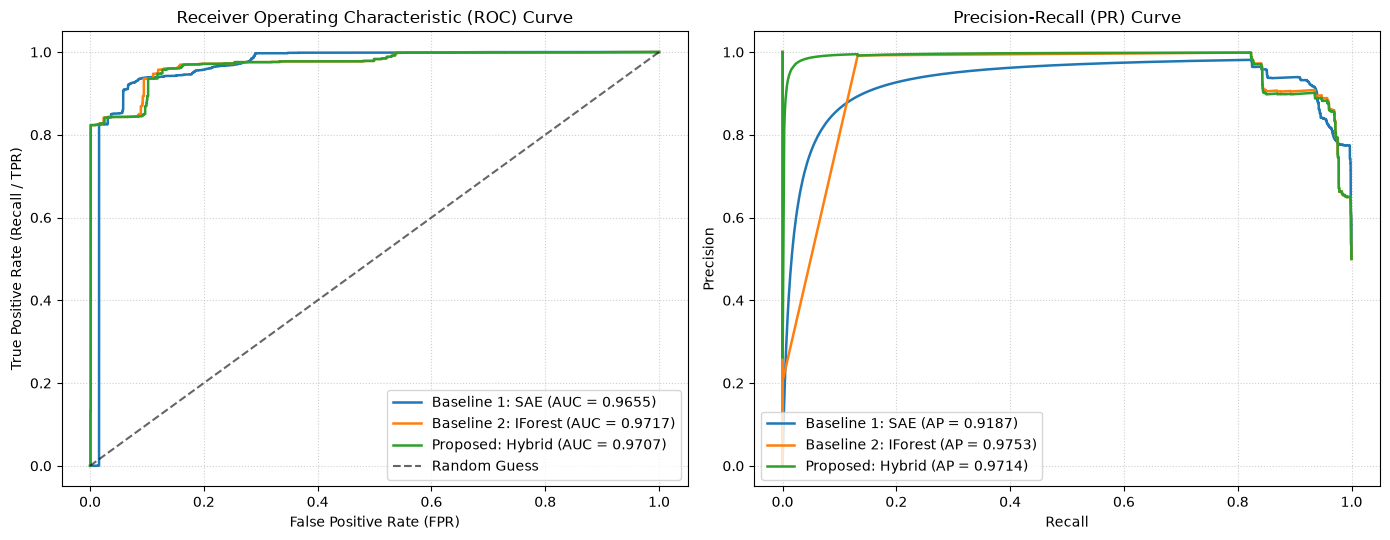

Grafik kurva evaluasi berhasil disimpan di: I:\skripsi\NIDS\notebooks\results\roc_pr_curves.png

[SELESAI] Seluruh modul Part 1 hingga Part 5 telah berhasil dieksekusi.


In [10]:
# 1. Simpan Metrik ke results/metrics.json
metrics_payload = {
    "config": {
        "alpha": ALPHA,
        "threshold_percentile": THRESHOLD_PERCENTILE,
        "latent_dim": LATENT_DIM,
        "total_test_samples": len(y_test),
        "normal_samples": int((y_test == 0).sum()),
        "unseen_attack_samples": int((y_test == 1).sum()),
    },
    "thresholds": {
        "tau_sae": tau_sae,
        "tau_iforest": tau_iforest,
        "tau_hybrid": tau_hybrid,
    },
    "evaluation_metrics": results,
}

with open(METRICS_PATH, "w", encoding="utf-8") as f:
  json.dump(metrics_payload, f, indent=4)
print(f"Metrik evaluasi lengkap tersimpan di: {METRICS_PATH}")

# 2. Visualisasi Kurva ROC dan PR Curve
scores_dict = {
    "Baseline 1: SAE": sae_test_scores,
    "Baseline 2: IForest": if_test_scores,
    "Proposed: Hybrid": hybrid_test_scores,
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Plot ROC Curves
for name, scores in scores_dict.items():
  fpr_vals, tpr_vals, _ = roc_curve(y_test, scores)
  auc_val = auc(fpr_vals, tpr_vals)
  axes[0].plot(
      fpr_vals, tpr_vals, label=f"{name} (AUC = {auc_val:.4f})", linewidth=1.8
  )

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.6, label="Random Guess")
axes[0].set_title("Receiver Operating Characteristic (ROC) Curve", fontsize=12)
axes[0].set_xlabel("False Positive Rate (FPR)", fontsize=10)
axes[0].set_ylabel("True Positive Rate (Recall / TPR)", fontsize=10)
axes[0].grid(True, linestyle=":", alpha=0.6)
axes[0].legend(loc="lower right")

# Plot Precision-Recall Curves
for name, scores in scores_dict.items():
  prec_vals, rec_vals, _ = precision_recall_curve(y_test, scores)
  ap_val = average_precision_score(y_test, scores)
  axes[1].plot(
      rec_vals, prec_vals, label=f"{name} (AP = {ap_val:.4f})", linewidth=1.8
  )

axes[1].set_title("Precision-Recall (PR) Curve", fontsize=12)
axes[1].set_xlabel("Recall", fontsize=10)
axes[1].set_ylabel("Precision", fontsize=10)
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend(loc="lower left")

plt.tight_layout()
plt.savefig(CURVE_PLOT_PATH, dpi=300, bbox_inches="tight")
plt.show()

print(f"Grafik kurva evaluasi berhasil disimpan di: {CURVE_PLOT_PATH}")
print(
    "\n[SELESAI] Seluruh modul Part 1 hingga Part 5 telah berhasil dieksekusi."
)
